In [28]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 1: Imports & Configuration
# ============================================================
# This cell only prepares the environment. It does NOT read or
# analyze data. All paths and seeds live here as a single source
# of truth for the rest of the notebook.
# ============================================================

from __future__ import annotations

# --- Standard library --------------------------------------------------------
import json
import random
from pathlib import Path

# --- Third-party: data processing --------------------------------------------
import polars as pl
import numpy as np

# --- Third-party: visualization ----------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# --- Reproducibility seeds ---------------------------------------------------
# The project definition fixes SPLIT_SEED = 2026 and the masking rule.
# We define them here so every later sampling step can reuse them.
SPLIT_SEED = 2026
MASK_SEED = "digikala-semi-supervised-v1"

# --- Project paths -----------------------------------------------------------
PROJECT_ROOT = Path("/home/jvd/Desktop/persian-nlp-pipeline")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
COMMENTS_CSV = RAW_DIR / "digikala-comments.csv"
PRODUCTS_CSV = RAW_DIR / "digikala-products.csv"

# --- Polars display configuration (readability only) -------------------------
pl.Config.set_tbl_rows(20)          # show up to 20 rows in repr
pl.Config.set_tbl_cols(30)          # show up to 30 columns
pl.Config.set_fmt_str_lengths(80)   # truncate long strings to 80 chars
pl.Config.set_tbl_width_chars(200)  # wider table for many columns

# --- Matplotlib / Seaborn defaults -------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# --- Sanity check: paths exist ----------------------------------------------
for _p in (COMMENTS_CSV, PRODUCTS_CSV):
    assert _p.exists(), f"Missing expected file: {_p}"

print("Environment ready.")
print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"COMMENTS_CSV : {COMMENTS_CSV}  ({COMMENTS_CSV.stat().st_size / 1024**2:,.1f} MB)")
print(f"PRODUCTS_CSV : {PRODUCTS_CSV}  ({PRODUCTS_CSV.stat().st_size / 1024**2:,.1f} MB)")
print(f"SPLIT_SEED   : {SPLIT_SEED}")
print(f"pl version   : {pl.__version__}")

Environment ready.
PROJECT_ROOT : /home/jvd/Desktop/persian-nlp-pipeline
COMMENTS_CSV : /home/jvd/Desktop/persian-nlp-pipeline/data/raw/digikala-comments.csv  (1,219.3 MB)
PRODUCTS_CSV : /home/jvd/Desktop/persian-nlp-pipeline/data/raw/digikala-products.csv  (246.7 MB)
SPLIT_SEED   : 2026
pl version   : 2.1.0


In [32]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 2: First Look at CSV Schema
# ============================================================
# Goal: discover delimiter, encoding, column names, inferred dtypes,
# and the approximate row count BEFORE loading the full dataset.
# We use lazy scan_csv so that no data is materialized until needed.
# ============================================================

import csv

def sniff_csv(path: Path, n_bytes: int = 64 * 1024) -> dict:
    """
    Peek at the first n_bytes of a CSV file to detect encoding,
    delimiter, and whether the file starts with a UTF-8 BOM.

    Returns a dict with keys: encoding, delimiter, has_bom, first_line.
    """
    raw = path.open("rb").read(n_bytes)

    # Detect BOM (byte order mark). Excel often writes UTF-8 with BOM.
    has_bom = raw.startswith(b"\xef\xbb\xbf")
    encoding = "utf-8-sig" if has_bom else "utf-8"

    # Decode with errors="replace" so a partially-cut multibyte char
    # at the end of the sample does not crash detection.
    text = raw.decode(encoding, errors="replace")
    first_line = text.splitlines()[0] if text else ""

    # csv.Sniffer guesses the delimiter from the first sample.
    try:
        dialect = csv.Sniffer().sniff(first_line, delimiters=",;\t|")
        delimiter = dialect.delimiter
    except csv.Error:
        # Fallback: pick the delimiter with the highest count.
        delimiter = max(",;\t|", key=first_line.count)

    return {
        "encoding": encoding,
        "delimiter": delimiter,
        "has_bom": has_bom,
        "first_line": first_line,
    }


# --- 1. Sniff the comments file ---------------------------------------------
info_comments = sniff_csv(COMMENTS_CSV)
print("=" * 60)
print("digikala-comments.csv")
print("=" * 60)
print(f"encoding   : {info_comments['encoding']}")
print(f"delimiter  : {info_comments['delimiter']!r}")
print(f"has BOM    : {info_comments['has_bom']}")
print(f"first line : {info_comments['first_line'][:200]}")

# --- 2. Lazy scan: schema without loading data ------------------------------
comments_lf = pl.scan_csv(
    COMMENTS_CSV,
    separator=info_comments["delimiter"],
    encoding="utf8",
    infer_schema_length=10_000,
    ignore_errors=False,
)

comments_schema = comments_lf.collect_schema()
print("\nInferred schema (column -> dtype):")
for name, dtype in comments_schema.items():
    print(f"  {name:<25} {dtype}")

# --- 3. Approximate row count -----------------------------------------------
# This still reads the file, but only keeps a single integer in memory.
n_rows_comments = comments_lf.select(pl.len()).collect().item()
print(f"\nApprox. row count (comments): {n_rows_comments:,}")

# --- 4. Peek at the first 3 rows --------------------------------------------
print("\nFirst 3 rows (comments):")
print(comments_lf.head(3).collect())

# --- 5. Same sniff for the products file ------------------------------------
info_products = sniff_csv(PRODUCTS_CSV)
print("\n" + "=" * 60)
print("digikala-products.csv")
print("=" * 60)
print(f"encoding   : {info_products['encoding']}")
print(f"delimiter  : {info_products['delimiter']!r}")
print(f"has BOM    : {info_products['has_bom']}")
print(f"first line : {info_products['first_line'][:200]}")

products_lf = pl.scan_csv(
    PRODUCTS_CSV,
    separator=info_products["delimiter"],
    encoding="utf8",
    infer_schema_length=10_000,
    ignore_errors=False,
)
products_schema = products_lf.collect_schema()
print("\nInferred schema (column -> dtype):")
for name, dtype in products_schema.items():
    print(f"  {name:<25} {dtype}")

n_rows_products = products_lf.select(pl.len()).collect().item()
print(f"\nApprox. row count (products): {n_rows_products:,}")

print("\nFirst 3 rows (products):")
print(products_lf.head(3).collect())

digikala-comments.csv
encoding   : utf-8-sig
delimiter  : ','
has BOM    : True
first line : id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate

Inferred schema (column -> dtype):
  id                        Int64
  title                     String
  body                      String
  created_at                String
  rate                      Float64
  recommendation_status     String
  is_buyer                  Boolean
  product_id                Int64
  advantages                String
  disadvantages             String
  likes                     Int64
  dislikes                  Int64
  seller_title              String
  seller_code               String
  true_to_size_rate         String

Approx. row count (comments): 6,156,289

First 3 rows (comments):
shape: (3, 15)
┌──────────┬───────────────┬───────────────┬───────────────┬──────┬───────────────┬──────────┬────────────┬────

In [33]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 3: Initial Dataset Inspection
# ============================================================
# Goal: peek at the ACTUAL CONTENT of the comments dataset:
#   - exact values of recommendation_status
#   - range and value granularity of rate
#   - null counts per column
#   - a few full-length body examples to judge Persian text quality
# This is diagnostic only; no cleaning or transformation happens here.
# ============================================================

# --- 1. Exact label vocabulary for recommendation_status --------------------
# This decides whether the three canonical classes from the Definition
# exist as-is, or need a documented mapping.
rec_counts = (
    comments_lf
    .group_by("recommendation_status")
    .agg(pl.len().alias("n"))
    .sort("n", descending=True)
    .collect()
)
print("recommendation_status — exact values and counts:")
print(rec_counts)
print()

# --- 2. rate: range, granularity, and coarse distribution -------------------
rate_stats = (
    comments_lf
    .select(
        pl.col("rate").min().alias("min"),
        pl.col("rate").max().alias("max"),
        pl.col("rate").mean().alias("mean"),
        pl.col("rate").median().alias("median"),
        pl.col("rate").std().alias("std"),
        pl.col("rate").n_unique().alias("n_unique"),
        pl.col("rate").null_count().alias("n_null"),
    )
    .collect()
)
print("rate — summary statistics (full data):")
print(rate_stats)
print()

# Value counts of rate (rounded to 1 decimal) to see the granularity.
rate_value_counts = (
    comments_lf
    .select(pl.col("rate").round(1))
    .group_by("rate")
    .agg(pl.len().alias("n"))
    .sort("rate")
    .collect()
)
print("rate — value counts (rounded to 0.1):")
print(rate_value_counts)
print()

# --- 3. Null counts per column (preview of A2) ------------------------------
null_counts = (
    comments_lf
    .select([pl.col(c).null_count().alias(c) for c in comments_schema.keys()])
    .collect()
)
print("Null counts per column (comments):")
print(null_counts.transpose(include_header=True,
                            column_names=["null_count"]))
print()

# --- 4. A few full-length body examples (no truncation) --------------------
# We deliberately disable string truncation so we can see the real text:
# Persian half-spaces, Arabic vs Persian yeh/kaf, emojis, stray characters.
with pl.Config(fmt_str_lengths=1000, tbl_width_chars=250):
    sample_bodies = (
        comments_lf
        .select("id", "body")
        .filter(pl.col("body").is_not_null() & (pl.col("body").str.len_chars() > 0))
        .head(5)
        .collect()
    )
    print("Five raw `body` examples (full length):")
    for row in sample_bodies.iter_rows(named=True):
        print("-" * 70)
        print(f"id={row['id']}")
        print(row["body"])
    print("-" * 70)

recommendation_status — exact values and counts:
shape: (4, 2)
┌───────────────────────┬─────────┐
│ recommendation_status ┆ n       │
│ ---                   ┆ ---     │
│ str                   ┆ u32     │
╞═══════════════════════╪═════════╡
│ recommended           ┆ 4162839 │
│ nan                   ┆ 894426  │
│ no_idea               ┆ 594121  │
│ not_recommended       ┆ 504903  │
└───────────────────────┴─────────┘

rate — summary statistics (full data):
shape: (1, 7)
┌─────┬────────┬──────────┬────────┬──────────┬──────────┬────────┐
│ min ┆ max    ┆ mean     ┆ median ┆ std      ┆ n_unique ┆ n_null │
│ --- ┆ ---    ┆ ---      ┆ ---    ┆ ---      ┆ ---      ┆ ---    │
│ f64 ┆ f64    ┆ f64      ┆ f64    ┆ f64      ┆ u32      ┆ u32    │
╞═════╪════════╪══════════╪════════╪══════════╪══════════╪════════╡
│ 0.0 ┆ 2500.0 ┆ 3.648286 ┆ 4.0    ┆ 1.861854 ┆ 178      ┆ 0      │
└─────┴────────┴──────────┴────────┴──────────┴──────────┴────────┘

rate — value counts (rounded to 0.1):
shape: (

In [34]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 4: Quality Gate (diagnostic only)
# ============================================================
# Goal: measure the EXACT extent of data-quality issues before any
# cleaning is decided. Nothing is dropped or transformed here.
#   1. sentinel values in string columns ("nan", "", "null", "None", "NaN")
#   2. rate records outside [0, 5]
#   3. duplicate ids
#   4. coarse body-length quantiles (to inform max_length later)
# ============================================================

# --- 1. Sentinel-value discovery in string columns -------------------------
# We check the most common fake-null tokens. A column "looks like" it has
# hidden nulls if any of these tokens appears with non-trivial frequency.
SENTINELS = ["nan", "NaN", "null", "None", ""]

string_cols = [
    name for name, dtype in comments_schema.items()
    if dtype == pl.String
]

sentinel_rows = []
for col in string_cols:
    # Build one aggregation that counts each sentinel token in this column.
    aggs = [
        (pl.col(col) == tok).sum().alias(f"n_{tok!r}")
        for tok in SENTINELS
    ]
    counts = comments_lf.select(aggs).collect().row(0)
    sentinel_rows.append((col, *counts))

# Turn the list of tuples into a tidy Polars DataFrame for display.
sentinel_df = pl.DataFrame(
    sentinel_rows,
    schema=["column"] + [f"n_{tok!r}" for tok in SENTINELS],
    orient="row",
)

print("Sentinel values in string columns (raw counts, full data):")
with pl.Config(tbl_rows=30, tbl_width_chars=220):
    print(sentinel_df)
print()

# --- 2. rate outside [0, 5] ------------------------------------------------
rate_out_of_range = (
    comments_lf
    .filter((pl.col("rate") < 0) | (pl.col("rate") > 5))
    .select(pl.len().alias("n_out_of_range"))
    .collect()
    .item()
)
print(f"rate outside [0, 5] : {rate_out_of_range:,}")

# --- 3. Duplicate ids ------------------------------------------------------
n_ids_total = comments_lf.select(pl.len()).collect().item()
n_ids_unique = comments_lf.select(pl.col("id").n_unique()).collect().item()
print(f"id — total rows     : {n_ids_total:,}")
print(f"id — unique values  : {n_ids_unique:,}")
print(f"id — duplicates     : {n_ids_total - n_ids_unique:,}")
print()

# --- 4. Coarse body-length quantiles ---------------------------------------
# Use character length (not bytes) because Persian uses 2-byte characters.
body_len_stats = (
    comments_lf
    .select(
        pl.col("body").str.len_chars().min().alias("min"),
        pl.col("body").str.len_chars().quantile(0.50).alias("p50"),
        pl.col("body").str.len_chars().quantile(0.90).alias("p90"),
        pl.col("body").str.len_chars().quantile(0.95).alias("p95"),
        pl.col("body").str.len_chars().quantile(0.99).alias("p99"),
        pl.col("body").str.len_chars().max().alias("max"),
    )
    .collect()
)
print("body — character-length quantiles (full data):")
print(body_len_stats)

Sentinel values in string columns (raw counts, full data):
shape: (9, 6)
┌───────────────────────┬─────────┬─────────┬──────────┬──────────┬──────┐
│ column                ┆ n_'nan' ┆ n_'NaN' ┆ n_'null' ┆ n_'None' ┆ n_'' │
│ ---                   ┆ ---     ┆ ---     ┆ ---      ┆ ---      ┆ ---  │
│ str                   ┆ i64     ┆ i64     ┆ i64      ┆ i64      ┆ i64  │
╞═══════════════════════╪═════════╪═════════╪══════════╪══════════╪══════╡
│ title                 ┆ 2865062 ┆ 0       ┆ 0        ┆ 0        ┆ 0    │
│ body                  ┆ 637     ┆ 0       ┆ 0        ┆ 0        ┆ 0    │
│ created_at            ┆ 0       ┆ 0       ┆ 0        ┆ 0        ┆ 0    │
│ recommendation_status ┆ 894426  ┆ 0       ┆ 0        ┆ 0        ┆ 0    │
│ advantages            ┆ 5448084 ┆ 0       ┆ 0        ┆ 0        ┆ 0    │
│ disadvantages         ┆ 5744017 ┆ 0       ┆ 0        ┆ 0        ┆ 0    │
│ seller_title          ┆ 302181  ┆ 0       ┆ 0        ┆ 0        ┆ 0    │
│ seller_code           ┆ 3

In [36]:
# --- 5. Review-count distribution per product ------------------------------
# Keep as LazyFrame with .cache() so the group_by runs exactly once,
# but we can still query it multiple times cheaply.
reviews_per_product_lf = (
    comments_lf
    .group_by("product_id")
    .agg(pl.len().alias("n_reviews"))
    .cache()
)

reviews_per_product_summary = (
    reviews_per_product_lf
    .select(
        pl.col("n_reviews").min().alias("min"),
        pl.col("n_reviews").quantile(0.25).alias("p25"),
        pl.col("n_reviews").median().alias("p50"),
        pl.col("n_reviews").quantile(0.75).alias("p75"),
        pl.col("n_reviews").quantile(0.90).alias("p90"),
        pl.col("n_reviews").quantile(0.99).alias("p99"),
        pl.col("n_reviews").max().alias("max"),
        pl.col("n_reviews").mean().alias("mean"),
        pl.col("n_reviews").sum().alias("total_reviews"),
    )
    .collect()
)
print("Reviews per product — summary (across all products with ≥1 review):")
print(reviews_per_product_summary)
print()

# --- 6. Top 10 products by review count (evidence of concentration) -------
top_products = (
    reviews_per_product_lf
    .sort("n_reviews", descending=True)
    .head(10)
    .collect()
)
print("Top 10 products by review count:")
print(top_products)
print()

# --- 7. Shape of the "one review" tail ------------------------------------
one_review_products = (
    reviews_per_product_lf
    .filter(pl.col("n_reviews") == 1)
    .select(pl.len())
    .collect()
    .item()
)
print(f"Products with exactly 1 review : {one_review_products:,}")

five_or_less = (
    reviews_per_product_lf
    .filter(pl.col("n_reviews") <= 5)
    .select(pl.len())
    .collect()
    .item()
)
print(f"Products with ≤5 reviews       : {five_or_less:,}")

Reviews per product — summary (across all products with ≥1 review):
shape: (1, 9)
┌─────┬─────┬─────┬──────┬──────┬───────┬─────┬───────────┬───────────────┐
│ min ┆ p25 ┆ p50 ┆ p75  ┆ p90  ┆ p99   ┆ max ┆ mean      ┆ total_reviews │
│ --- ┆ --- ┆ --- ┆ ---  ┆ ---  ┆ ---   ┆ --- ┆ ---       ┆ ---           │
│ u32 ┆ f64 ┆ f64 ┆ f64  ┆ f64  ┆ f64   ┆ u32 ┆ f64       ┆ u32           │
╞═════╪═════╪═════╪══════╪══════╪═══════╪═════╪═══════════╪═══════════════╡
│ 1   ┆ 1.0 ┆ 4.0 ┆ 13.0 ┆ 46.0 ┆ 200.0 ┆ 400 ┆ 18.565463 ┆ 6156289       │
└─────┴─────┴─────┴──────┴──────┴───────┴─────┴───────────┴───────────────┘

Top 10 products by review count:
shape: (10, 2)
┌────────────┬───────────┐
│ product_id ┆ n_reviews │
│ ---        ┆ ---       │
│ i64        ┆ u32       │
╞════════════╪═══════════╡
│ 4332510    ┆ 400       │
│ 3331597    ┆ 400       │
│ 4095187    ┆ 400       │
│ 2156856    ┆ 279       │
│ 3392906    ┆ 250       │
│ 82098      ┆ 238       │
│ 5715766    ┆ 233       │
│ 4012333    

In [37]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 6: A2 Missing-Value Patterns
# ============================================================
# Goal (per Definition):
#   - Per-column missing count and percentage (sentinel-aware)
#   - Is missing recommendation_status random or structural?
#     Compare the missing vs non-missing groups on:
#       * is_buyer distribution
#       * rate distribution
#       * product frequency (reviews per product)
# Nothing is dropped or modified here.
# ============================================================

# --- 1. Sentinel-aware missing table for every column ----------------------
# "Missing" here means: actual null OR a sentinel string.
# Numeric columns can only be null (they cannot contain string sentinels).
SENTINEL_SET = {"nan", "NaN", "null", "None"}

def missing_expr(col: str, dtype) -> pl.Expr:
    """Return a boolean expression: True if the cell is missing."""
    if dtype in (pl.String, pl.Utf8):
        return (
            pl.col(col).is_null()
            | pl.col(col).is_in(list(SENTINEL_SET))
            | (pl.col(col) == "")
        )
    return pl.col(col).is_null()

missing_aggs = [
    missing_expr(name, dtype).sum().alias(name)
    for name, dtype in comments_schema.items()
]
missing_counts = comments_lf.select(missing_aggs).collect().row(0)

missing_table = pl.DataFrame(
    {
        "column": list(comments_schema.keys()),
        "missing_count": list(missing_counts),
    }
).with_columns(
    (pl.col("missing_count") / n_rows_comments * 100)
    .round(3)
    .alias("missing_pct")
)

print("Per-column missing counts (sentinel-aware):")
with pl.Config(tbl_rows=30):
    print(missing_table.sort("missing_pct", descending=True))
print()

# --- 2. Group definition: recommendation_status missing vs present ---------
# We define a boolean column so we can reuse it in multiple group-bys.
rec_is_missing = pl.col("recommendation_status").is_in(list(SENTINEL_SET))
rec_is_present = ~rec_is_missing

# --- 3. Is missing related to is_buyer? -----------------------------------
buyer_breakdown = (
    comments_lf
    .group_by(
        rec_is_missing.alias("rec_missing"),
        pl.col("is_buyer"),
    )
    .agg(pl.len().alias("n"))
    .sort("rec_missing", "is_buyer")
    .collect()
)
print("recommendation_status missing × is_buyer:")
print(buyer_breakdown)
print()

# --- 4. Is missing related to rate? ---------------------------------------
rate_breakdown = (
    comments_lf
    .group_by(rec_is_missing.alias("rec_missing"))
    .agg(
        pl.len().alias("n"),
        pl.col("rate").mean().alias("rate_mean"),
        pl.col("rate").median().alias("rate_median"),
        pl.col("rate").std().alias("rate_std"),
        (pl.col("rate") == 0.0).mean().alias("frac_rate_0"),
        (pl.col("rate") == 5.0).mean().alias("frac_rate_5"),
    )
    .sort("rec_missing")
    .collect()
)
print("recommendation_status missing × rate (aggregate):")
print(rate_breakdown)
print()

# --- 5. Is missing related to product frequency? --------------------------
# Join the product-level review count onto each row, then compare mean/median.
rec_vs_freq = (
    comments_lf
    .join(
        reviews_per_product_lf,
        on="product_id",
        how="left",
    )
    .group_by(rec_is_missing.alias("rec_missing"))
    .agg(
        pl.len().alias("n"),
        pl.col("n_reviews").mean().alias("prod_freq_mean"),
        pl.col("n_reviews").median().alias("prod_freq_median"),
        pl.col("n_reviews").quantile(0.90).alias("prod_freq_p90"),
    )
    .sort("rec_missing")
    .collect()
)
print("recommendation_status missing × product frequency (reviews per product):")
print(rec_vs_freq)
print()

# --- 6. Cross-tab: missing_rate by is_buyer (the cleanest summary) --------
missing_rate_by_buyer = (
    comments_lf
    .group_by("is_buyer")
    .agg(
        pl.len().alias("n_total"),
        rec_is_missing.sum().alias("n_missing"),
    )
    .with_columns(
        (pl.col("n_missing") / pl.col("n_total") * 100)
        .round(3)
        .alias("missing_pct")
    )
    .sort("is_buyer")
    .collect()
)
print("Missing rate of recommendation_status by is_buyer:")
print(missing_rate_by_buyer)

Per-column missing counts (sentinel-aware):
shape: (15, 3)
┌───────────────────────┬───────────────┬─────────────┐
│ column                ┆ missing_count ┆ missing_pct │
│ ---                   ┆ ---           ┆ ---         │
│ str                   ┆ i64           ┆ f64         │
╞═══════════════════════╪═══════════════╪═════════════╡
│ true_to_size_rate     ┆ 6065516       ┆ 98.526      │
│ disadvantages         ┆ 5744017       ┆ 93.303      │
│ advantages            ┆ 5448084       ┆ 88.496      │
│ title                 ┆ 2865062       ┆ 46.539      │
│ recommendation_status ┆ 894426        ┆ 14.529      │
│ seller_title          ┆ 302181        ┆ 4.908       │
│ seller_code           ┆ 302181        ┆ 4.908       │
│ body                  ┆ 637           ┆ 0.01        │
│ id                    ┆ 0             ┆ 0.0         │
│ created_at            ┆ 0             ┆ 0.0         │
│ rate                  ┆ 0             ┆ 0.0         │
│ is_buyer              ┆ 0             ┆ 0.0

recommendation_status — distribution (missing excluded):
shape: (3, 3)
┌───────────────────────┬─────────┬────────────────┐
│ recommendation_status ┆ n       ┆ pct_supervised │
│ ---                   ┆ ---     ┆ ---            │
│ str                   ┆ u32     ┆ f64            │
╞═══════════════════════╪═════════╪════════════════╡
│ recommended           ┆ 4162839 ┆ 79.11          │
│ no_idea               ┆ 594121  ┆ 11.29          │
│ not_recommended       ┆ 504903  ┆ 9.6            │
└───────────────────────┴─────────┴────────────────┘

rate — full descriptive statistics (raw, includes the outlier):
shape: (1, 10)
┌─────┬────────┬──────────┬────────┬──────────┬─────┬─────┬─────┬─────┬──────────┐
│ min ┆ max    ┆ mean     ┆ median ┆ std      ┆ p25 ┆ p75 ┆ p95 ┆ p99 ┆ n_unique │
│ --- ┆ ---    ┆ ---      ┆ ---    ┆ ---      ┆ --- ┆ --- ┆ --- ┆ --- ┆ ---      │
│ f64 ┆ f64    ┆ f64      ┆ f64    ┆ f64      ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ u32      │
╞═════╪════════╪══════════╪════════╪════

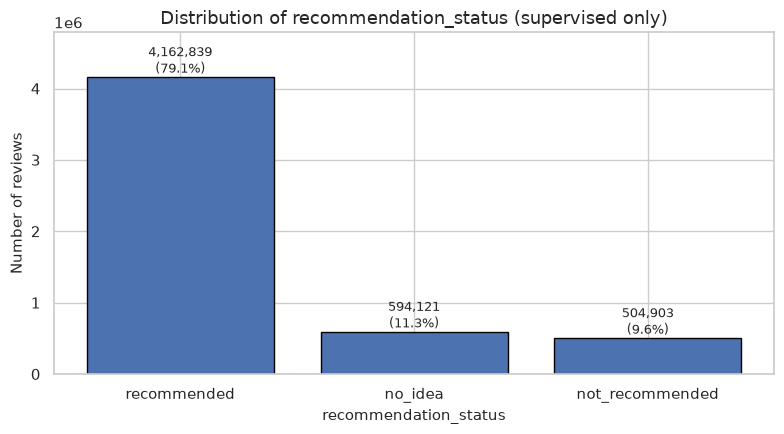

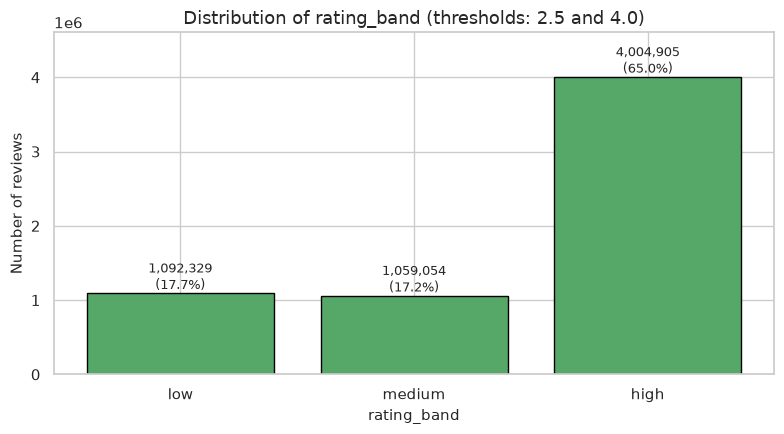

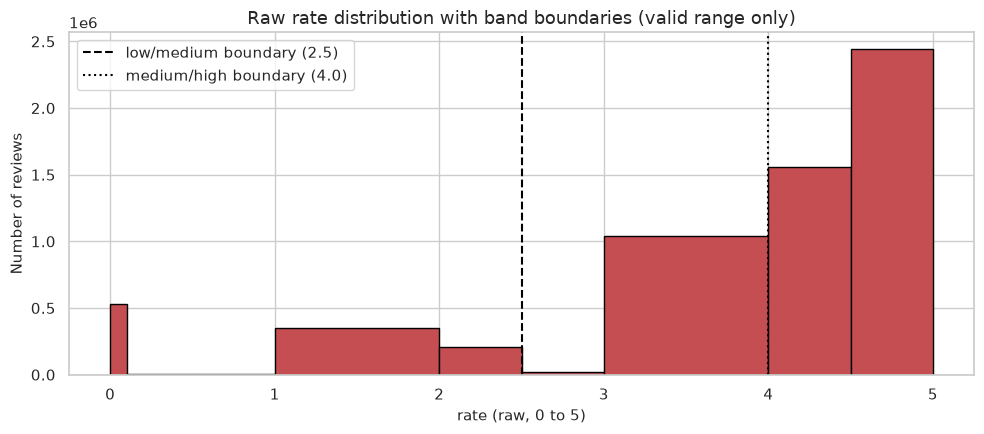

In [38]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 7: A3 Target Distributions
# ============================================================
# Goal (per Definition):
#   - counts and percentages for each recommendation class
#   - counts and percentages for each rating_band
#   - full descriptive statistics for raw rate
#   - compare rate with recommendation_status
#   - two required plots: recommendation_status, rating_band
#   - one optional plot: raw rate histogram with band boundaries
#
# Band thresholds (fixed by the Definition):
#   low    : 0.0 <= rate < 2.5
#   medium : 2.5 <= rate < 4.0
#   high   : 4.0 <= rate <= 5.0
# Records with rate outside [0, 5] are invalid for rating_band.
# ============================================================

# --- 1. recommendation_status distribution (supervised only) --------------
rec_dist = (
    comments_lf
    .filter(~pl.col("recommendation_status").is_in(["nan", "NaN", "null", "None", ""]))
    .group_by("recommendation_status")
    .agg(pl.len().alias("n"))
    .with_columns(
        (pl.col("n") / pl.col("n").sum() * 100).round(2).alias("pct_supervised")
    )
    .sort("n", descending=True)
    .collect()
)
print("recommendation_status — distribution (missing excluded):")
print(rec_dist)
print()

# --- 2. rate — full descriptive statistics --------------------------------
rate_full = (
    comments_lf
    .select(
        pl.col("rate").min().alias("min"),
        pl.col("rate").max().alias("max"),
        pl.col("rate").mean().alias("mean"),
        pl.col("rate").median().alias("median"),
        pl.col("rate").std().alias("std"),
        pl.col("rate").quantile(0.25).alias("p25"),
        pl.col("rate").quantile(0.75).alias("p75"),
        pl.col("rate").quantile(0.95).alias("p95"),
        pl.col("rate").quantile(0.99).alias("p99"),
        pl.col("rate").n_unique().alias("n_unique"),
    )
    .collect()
)
print("rate — full descriptive statistics (raw, includes the outlier):")
print(rate_full)
print()

# --- 3. Fraction of fractional rates --------------------------------------
# `rate != floor(rate)` is True for non-integer values (e.g. 4.5).
frac_fractional = (
    comments_lf
    .select(
        (pl.col("rate") != pl.col("rate").floor())
        .mean()
        .alias("frac_fractional")
    )
    .collect()
    .item()
)
print(f"fraction of non-integer rate values : {frac_fractional:.4%}")
print()

# --- 4. rate x recommendation_status (crosstab, supervised only) ----------
rate_by_rec = (
    comments_lf
    .filter(~pl.col("recommendation_status").is_in(["nan", "NaN", "null", "None", ""]))
    .group_by("recommendation_status")
    .agg(
        pl.len().alias("n"),
        pl.col("rate").mean().alias("rate_mean"),
        pl.col("rate").median().alias("rate_median"),
        pl.col("rate").std().alias("rate_std"),
    )
    .sort("n", descending=True)
    .collect()
)
print("rate × recommendation_status:")
print(rate_by_rec)
print()

# --- 5. rating_band (per Definition) --------------------------------------
# Only records with 0 <= rate <= 5 are valid for rating_band.
# We report both the valid counts and the single invalid record.
rating_band_expr = (
    pl.when(pl.col("rate") < 2.5).then(pl.lit("low"))
      .when(pl.col("rate") < 4.0).then(pl.lit("medium"))
      .when(pl.col("rate") <= 5.0).then(pl.lit("high"))
      .otherwise(pl.lit("invalid"))
      .alias("rating_band")
)

band_dist = (
    comments_lf
    .select(rating_band_expr)
    .group_by("rating_band")
    .agg(pl.len().alias("n"))
    .with_columns(
        (pl.col("n") / pl.col("n").sum() * 100).round(2).alias("pct")
    )
    .sort("rating_band")
    .collect()
)
print("rating_band — distribution (valid bands + invalid):")
print(band_dist)
print()

# --- 6. Plot 1: recommendation_status -------------------------------------
fig, ax = plt.subplots(figsize=(8, 4.5))
rec_pdf = rec_dist.to_pandas()
ax.bar(rec_pdf["recommendation_status"], rec_pdf["n"], color="#4C72B0", edgecolor="black")
ax.set_title("Distribution of recommendation_status (supervised only)")
ax.set_ylabel("Number of reviews")
ax.set_xlabel("recommendation_status")
for i, (label, n) in enumerate(zip(rec_pdf["recommendation_status"], rec_pdf["n"])):
    ax.text(i, n, f"{n:,}\n({rec_pdf['pct_supervised'][i]:.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, rec_pdf["n"].max() * 1.15)
plt.tight_layout()
plt.show()

# --- 7. Plot 2: rating_band ----------------------------------------------
band_pdf = (
    band_dist
    .filter(pl.col("rating_band") != "invalid")  # only valid bands in the plot
    .to_pandas()
)
# Enforce the ordinal order: low < medium < high
order = ["low", "medium", "high"]
band_pdf["rating_band"] = band_pdf["rating_band"].astype("category").cat.set_categories(order)
band_pdf = band_pdf.sort_values("rating_band")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(band_pdf["rating_band"], band_pdf["n"], color="#55A868", edgecolor="black")
ax.set_title("Distribution of rating_band (thresholds: 2.5 and 4.0)")
ax.set_ylabel("Number of reviews")
ax.set_xlabel("rating_band")
for i, (label, n) in enumerate(zip(band_pdf["rating_band"], band_pdf["n"])):
    ax.text(i, n, f"{n:,}\n({band_pdf['pct'].iloc[i]:.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, band_pdf["n"].max() * 1.15)
plt.tight_layout()
plt.show()

# --- 8. Plot 3: raw rate histogram with band boundaries -------------------
# This plot justifies the chosen thresholds visually.
rate_pdf = (
    comments_lf
    .filter((pl.col("rate") >= 0) & (pl.col("rate") <= 5))
    .select("rate")
    .collect()
    .to_pandas()
)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(rate_pdf["rate"], bins=[0, 0.1, 0.5, 1.0, 2.0, 2.5, 3.0, 4.0, 4.5, 5.0],
        color="#C44E52", edgecolor="black", align="mid")
ax.axvline(2.5, color="black", linestyle="--", linewidth=1.5, label="low/medium boundary (2.5)")
ax.axvline(4.0, color="black", linestyle=":",  linewidth=1.5, label="medium/high boundary (4.0)")
ax.set_title("Raw rate distribution with band boundaries (valid range only)")
ax.set_xlabel("rate (raw, 0 to 5)")
ax.set_ylabel("Number of reviews")
ax.legend()
plt.tight_layout()
plt.show()

Body length — global statistics (full data):
shape: (1, 12)
┌───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ chars_min ┆ chars_p50 ┆ chars_p90 ┆ chars_p95 ┆ chars_p99 ┆ chars_max ┆ words_min ┆ words_p50 ┆ words_p90 ┆ words_p95 ┆ words_p99 ┆ words_max │
│ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ u32       ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ u32       ┆ u32       ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ u32       │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 1         ┆ 29.0      ┆ 106.0     ┆ 152.0     ┆ 297.0     ┆ 4000      ┆ 1         ┆ 6.0       ┆ 22.0      ┆ 31.0      ┆ 61.0      ┆ 908       │
└───────────┴───────────┴───────────┴───────────┴───────────┴───

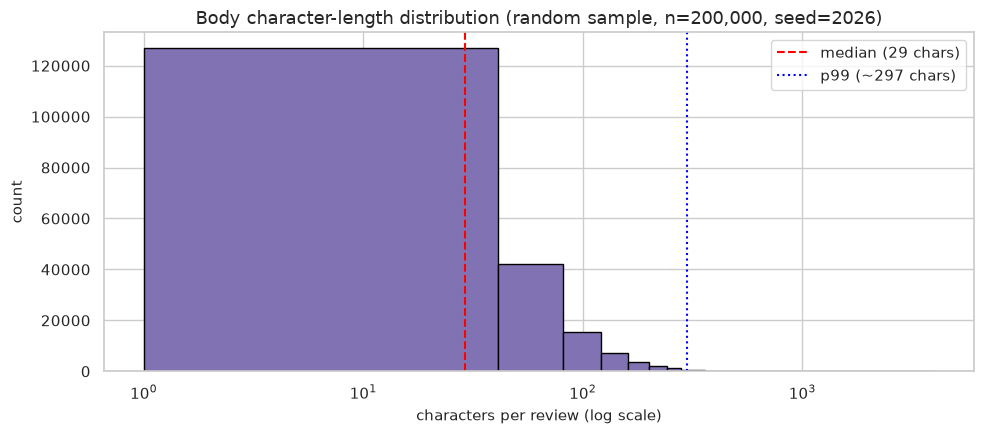

In [39]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 8: A4 Text-Length Analysis
# ============================================================
# Goal (per Definition):
#   - body length in characters and words
#   - median, upper percentiles, very short, very long
#   - length distribution by class (recommendation_status and rating_band)
#   - one plot (the 4th required plot in A7)
#   - direct input to the Transformer max_length decision
# ============================================================

# --- 1. Character and word length per row (LazyFrame) --------------------
# len_chars: Unicode code points (the number the user perceives as "characters")
# len_bytes: bytes in UTF-8 (used by some backend libraries, not shown here)
# split_whitespace: robust to multiple spaces, tabs, newlines
body_lf = comments_lf.select(
    pl.col("id"),
    pl.col("recommendation_status"),
    pl.col("rate"),
    pl.col("body"),
    pl.col("body").str.len_chars().alias("n_chars"),
    pl.col("body").str.split(by=" ").list.len().alias("n_tokens_ws"),
    pl.col("body").str.split(by=" ").list.eval(
        pl.element().filter(pl.element().str.len_chars() > 0)
    ).list.len().alias("n_words"),
)

# --- 2. Global length statistics (characters and words) -----------------
len_stats = body_lf.select(
    # characters
    pl.col("n_chars").min().alias("chars_min"),
    pl.col("n_chars").quantile(0.50).alias("chars_p50"),
    pl.col("n_chars").quantile(0.90).alias("chars_p90"),
    pl.col("n_chars").quantile(0.95).alias("chars_p95"),
    pl.col("n_chars").quantile(0.99).alias("chars_p99"),
    pl.col("n_chars").max().alias("chars_max"),
    # words
    pl.col("n_words").min().alias("words_min"),
    pl.col("n_words").quantile(0.50).alias("words_p50"),
    pl.col("n_words").quantile(0.90).alias("words_p90"),
    pl.col("n_words").quantile(0.95).alias("words_p95"),
    pl.col("n_words").quantile(0.99).alias("words_p99"),
    pl.col("n_words").max().alias("words_max"),
).collect()
print("Body length — global statistics (full data):")
print(len_stats)
print()

# --- 3. Very short / very long counts ------------------------------------
short_counts = body_lf.select(
    (pl.col("n_chars") < 10).sum().alias("n_chars_lt_10"),
    (pl.col("n_chars") < 20).sum().alias("n_chars_lt_20"),
    (pl.col("n_words") < 3).sum().alias("n_words_lt_3"),
).collect()
print("Very short reviews:")
print(short_counts)
print()

long_counts = body_lf.select(
    (pl.col("n_chars") > 300).sum().alias("n_chars_gt_300"),
    (pl.col("n_chars") > 500).sum().alias("n_chars_gt_500"),
    (pl.col("n_chars") > 1000).sum().alias("n_chars_gt_1000"),
).collect()
print("Very long reviews:")
print(long_counts)
print()

# --- 4. Length by recommendation_status (supervised only) ----------------
len_by_rec = (
    body_lf
    .filter(~pl.col("recommendation_status").is_in(["nan", "NaN", "null", "None", ""]))
    .group_by("recommendation_status")
    .agg(
        pl.len().alias("n"),
        pl.col("n_chars").mean().alias("chars_mean"),
        pl.col("n_chars").median().alias("chars_median"),
        pl.col("n_chars").quantile(0.90).alias("chars_p90"),
        pl.col("n_words").median().alias("words_median"),
    )
    .sort("n", descending=True)
    .collect()
)
print("Body length × recommendation_status:")
print(len_by_rec)
print()

# --- 5. Length by rating_band -------------------------------------------
band_expr = (
    pl.when(pl.col("rate") < 2.5).then(pl.lit("low"))
      .when(pl.col("rate") < 4.0).then(pl.lit("medium"))
      .when(pl.col("rate") <= 5.0).then(pl.lit("high"))
      .otherwise(pl.lit("invalid"))
      .alias("rating_band")
)
len_by_band = (
    body_lf
    .with_columns(band_expr)
    .filter(pl.col("rating_band") != "invalid")
    .group_by("rating_band")
    .agg(
        pl.len().alias("n"),
        pl.col("n_chars").median().alias("chars_median"),
        pl.col("n_words").median().alias("words_median"),
    )
    .sort("rating_band")
    .collect()
)
print("Body length × rating_band:")
print(len_by_band)
print()

# --- 6. Plot 4: body length distribution (log-scale) --------------------
# We take a bounded, reproducible sample for the plot because 6M points
# cannot be rendered efficiently. The count is documented below.
PLOT_SAMPLE_N = 200_000
len_sample = (
    body_lf
    .select("n_chars")
    .filter(pl.col("n_chars") > 0)
    .collect(engine="streaming")
    .sample(n=PLOT_SAMPLE_N, seed=SPLIT_SEED, with_replacement=False)
    .to_pandas()
)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(len_sample["n_chars"], bins=100, color="#8172B3", edgecolor="black")
ax.set_xscale("log")  # log scale because of the long tail
ax.axvline(29,  color="red",  linestyle="--", label="median (29 chars)")
ax.axvline(297, color="blue", linestyle=":",  label="p99 (~297 chars)")
ax.set_title(f"Body character-length distribution (random sample, n={PLOT_SAMPLE_N:,}, seed={SPLIT_SEED})")
ax.set_xlabel("characters per review (log scale)")
ax.set_ylabel("count")
ax.legend()
plt.tight_layout()
plt.show()

Duplicate IDs (summary):
shape: (1, 4)
┌───────────┬──────────────────────────┬─────────────────┬─────────────────────┐
│ n_dup_ids ┆ total_rows_in_dup_groups ┆ n_exact_dup_ids ┆ n_divergent_dup_ids │
│ ---       ┆ ---                      ┆ ---             ┆ ---                 │
│ u32       ┆ u32                      ┆ u32             ┆ u32                 │
╞═══════════╪══════════════════════════╪═════════════════╪═════════════════════╡
│ 3226      ┆ 6455                     ┆ 2911            ┆ 315                 │
└───────────┴──────────────────────────┴─────────────────┴─────────────────────┘

Example divergent duplicate IDs (top 5):
shape: (5, 3)
┌──────────┬────────┬─────────────────────┐
│ id       ┆ n_rows ┆ n_distinct_contents │
│ ---      ┆ ---    ┆ ---                 │
│ i64      ┆ u32    ┆ u32                 │
╞══════════╪════════╪═════════════════════╡
│ 54100922 ┆ 2      ┆ 2                   │
│ 32424494 ┆ 2      ┆ 2                   │
│ 54352656 ┆ 2      ┆ 2       

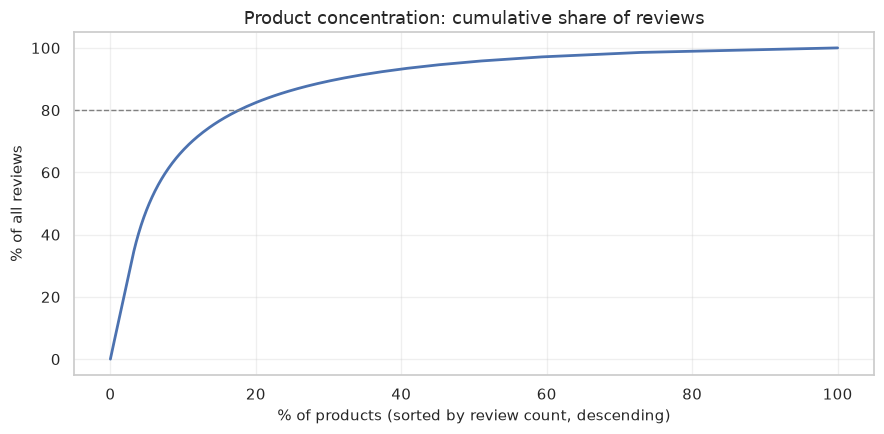

In [40]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 9: A5 Repetition, Conflicts, Concentration
# ============================================================
# Goal (per Definition):
#   1. duplicate IDs — exact vs content-divergent
#   2. duplicate body counts
#   3. identical texts with conflicting recommendation labels
#   4. product concentration (Lorenz-style cumulative share)
#   5. concrete evidence for product-grouped split
# Nothing is modified or removed here.
# ============================================================

# --- 1. Duplicate IDs: exact vs divergent --------------------------------
# Approach: hash all model-relevant columns per id, then compare
# how many distinct hashes exist for each id.
dup_id_stats = (
    comments_lf
    .select("id", "body", "rate", "recommendation_status")
    .group_by("id")
    .agg(
        pl.len().alias("n_rows"),
        pl.struct(["body", "rate", "recommendation_status"])
          .n_unique()
          .alias("n_distinct_contents"),
    )
    .filter(pl.col("n_rows") > 1)
    .select(
        pl.len().alias("n_dup_ids"),
        pl.col("n_rows").sum().alias("total_rows_in_dup_groups"),
        (pl.col("n_distinct_contents") == 1).sum().alias("n_exact_dup_ids"),
        (pl.col("n_distinct_contents") > 1).sum().alias("n_divergent_dup_ids"),
    )
    .collect()
)
print("Duplicate IDs (summary):")
print(dup_id_stats)
print()

# A few examples of divergent duplicates, if any, for inspection
divergent_examples = (
    comments_lf
    .select("id", "body", "rate", "recommendation_status")
    .group_by("id")
    .agg(
        pl.len().alias("n_rows"),
        pl.struct(["body", "rate", "recommendation_status"])
          .n_unique()
          .alias("n_distinct_contents"),
    )
    .filter((pl.col("n_rows") > 1) & (pl.col("n_distinct_contents") > 1))
    .sort("n_rows", descending=True)
    .head(5)
    .collect()
)
print("Example divergent duplicate IDs (top 5):")
print(divergent_examples)
print()

# --- 2. Duplicate body counts -------------------------------------------
# Two-sided: exact text match, independent of product.
dup_body_stats = (
    comments_lf
    .group_by("body")
    .agg(pl.len().alias("n_rows"))
    .filter(pl.col("n_rows") > 1)
    .select(
        pl.len().alias("n_dup_bodies"),
        pl.col("n_rows").sum().alias("total_rows_with_dup_body"),
        pl.col("n_rows").max().alias("max_dup_count"),
    )
    .collect()
)
print("Duplicate body texts:")
print(dup_body_stats)
print()

# --- 3. Identical texts with conflicting recommendation labels ----------
# Only supervised rows; ignore the 'nan' sentinel class.
# A body is "conflicting" if it has more than one distinct non-nan label.
conflict_stats = (
    comments_lf
    .filter(~pl.col("recommendation_status").is_in(["nan", "NaN", "null", "None", ""]))
    .group_by("body")
    .agg(
        pl.len().alias("n_rows"),
        pl.col("recommendation_status").n_unique().alias("n_labels"),
    )
    .filter((pl.col("n_rows") > 1) & (pl.col("n_labels") > 1))
    .select(
        pl.len().alias("n_conflicting_bodies"),
        pl.col("n_rows").sum().alias("total_rows_in_conflicts"),
    )
    .collect()
)
print("Identical texts with conflicting recommendation labels:")
print(conflict_stats)
print()

# A few examples of conflicting bodies
conflict_examples = (
    comments_lf
    .filter(~pl.col("recommendation_status").is_in(["nan", "NaN", "null", "None", ""]))
    .group_by("body")
    .agg(
        pl.len().alias("n_rows"),
        pl.col("recommendation_status").n_unique().alias("n_labels"),
    )
    .filter((pl.col("n_rows") > 1) & (pl.col("n_labels") > 1))
    .sort("n_rows", descending=True)
    .head(5)
    .collect()
)
print("Example conflicting bodies (top 5 by number of rows):")
with pl.Config(fmt_str_lengths=200, tbl_width_chars=200):
    print(conflict_examples)
print()

# --- 4. Product concentration (Pareto-style cumulative share) -----------
# reviews_per_product_lf was cached in cell 5, so this is cheap.
concentration = (
    reviews_per_product_lf
    .sort("n_reviews", descending=True)
    .with_columns(
        pl.col("n_reviews").cum_sum().alias("cum_reviews"),
    )
    .with_row_index("rank")
    .with_columns(
        ((pl.col("rank") + 1) / pl.len() * 100).alias("pct_products"),
        (pl.col("cum_reviews") / pl.col("cum_reviews").last() * 100).alias("pct_reviews"),
    )
    .collect()
)

# Extract points where cumulative review share crosses key thresholds
def first_pct_products_at(threshold_pct: float) -> dict:
    row = (
        concentration
        .filter(pl.col("pct_reviews") >= threshold_pct)
        .sort("pct_reviews")
        .head(1)
    )
    return {
        "threshold_reviews_pct": threshold_pct,
        "products_needed": int(row["rank"][0]) + 1,
        "products_needed_pct": float(row["pct_products"][0]),
    }

print("Product concentration — top-N products account for X% of all reviews:")
for pct in (25, 50, 80, 90):
    print(first_pct_products_at(pct))
print()

# --- 5. Plot 5: Lorenz-style cumulative concentration -------------------
# x = % products (sorted by review count, descending)
# y = % reviews captured
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(concentration["pct_products"], concentration["pct_reviews"],
        color="#4C72B0", linewidth=2)
ax.axhline(80, color="gray", linestyle="--", linewidth=1)
ax.set_title("Product concentration: cumulative share of reviews")
ax.set_xlabel("% of products (sorted by review count, descending)")
ax.set_ylabel("% of all reviews")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## A7. Descriptive-Analysis Deliverable

### Five defensible conclusions (from evidence)

1. **Both targets are strongly imbalanced but not equivalent.**
   `recommendation_status` has an 8.2:1 ratio (recommended 79.1%, no_idea 11.3%, not_recommended 9.6%).
   `rating_band` has a 3.8:1 ratio (high 65.0%, low 17.7%, medium 17.2%).
   Their correlation is strong but imperfect (`not_recommended` has rate μ=1.45, `no_idea` μ=2.92, `recommended` μ=3.93).
   **Implication:** Macro F1 is the primary metric; a single joint model may benefit both heads, but they should not be merged into one label.

2. **`recommendation_status` missingness is structural, not random.**
   100% of non-buyers lack the label; only 10.1% of buyers lack it.
   The missing group also has higher mean `rate` (4.04 vs 3.58), a higher fraction of 5-star ratings (48.6% vs 37.3%), and a lower fraction of 0-star ratings (2.8% vs 9.6%).
   **Implication:** supervised training is biased toward buyers who actively report; generalization to non-buyers is a documented limitation.

3. **`body` is nearly complete and moderate in length, but heavily skewed toward very short texts.**
   Only 637/6,156,289 (0.01%) bodies are missing.
   p50 = 29 chars / 6 words; 10.9% of reviews are under 10 chars; 34.1% under 20 chars.
   p99 = 297 chars / 61 words; only 0.96% exceed 300 chars.
   **Implication:** `max_length = 128` tokens (256 for extra safety) will fully capture ≥99% of reviews. Very short reviews are an unavoidable error-analysis category.

4. **Label noise is substantial: ~20% of supervised rows have conflicting labels for identical text.**
   31,942 distinct bodies are associated with more than one recommendation label, covering 1,221,047 rows.
   Top examples: "عالی" (85,211 rows, 3 labels), "خوب بود" (55,908, 3), "خوبه" (52,416, 3).
   **Implication:** no classifier can resolve this. This is an **irreducible noise floor**; Macro F1 cannot approach 1.0. This will be reported explicitly in the final report and will set realistic expectations.

5. **A product-grouped split is feasible and necessary.**
   331K distinct products in comments; the largest has 400 reviews (0.0065% of all).
   Product concentration is moderate: 2.31% of products cover 25% of reviews, 17.67% cover 80%.
   Review count per product: p50=4, p90=46, p99=200.
   **Implication:** a product-grouped 70/15/15 split is representative. It eliminates product leakage. The 91,944 single-review products are 8.4% of products; this is manageable in a stratified assignment.

### Links from findings to design decisions

| Finding | Decision |
|---|---|
| 8.2:1 class imbalance | Macro F1 primary; class weighting in Part C. |
| Structural missingness (buyer bias) | Document as limitation; do not re-label. |
| 20% conflicting labels | Set Macro F1 expectations; error analysis must include conflicts. |
| 36% duplicate bodies | Keep all; do not remove (test distribution would shift). |
| p99 = 297 chars | `max_length ∈ {128, 256}`; documented in Part C. |
| Moderate product concentration | Product-grouped split (70/15/15), no additional stratification required. |
| 3,226 duplicate IDs (315 divergent) | Drop exact duplicates; drop both rows in divergent groups (documented). |
| 1 record with rate=2500 | Mark as invalid for `rating_band` (Part B). |

### Bounded samples and seeds

- **Plot samples (length histogram, any future distribution plot):**
  `n = 200,000`, drawn with `sample(..., seed=SPLIT_SEED)`, where `SPLIT_SEED = 2026`.
  All global counts and quantiles reported above are computed on the **complete** dataset, not the sample.
- **No structural sampling** has been applied elsewhere in Part A.

### Deliverable artifacts produced by this notebook

- `artifacts/descriptive_summary.json` — machine-readable summary of every number in A1–A5 (see next code cell).

In [43]:
# ============================================================
# 01_descriptive_analysis.ipynb — Cell 10 (code): A7 Summary & JSON
# ============================================================
# Goal:
#   1. Assemble every number computed in A1–A5 into one Python dict.
#   2. Write it as artifacts/descriptive_summary.json for downstream use.
#   3. Print a human-readable one-page summary in the notebook.
#
# Nothing is recomputed on the full data here. We reuse variables that
# were already produced in cells 2–9 of this notebook.
# ============================================================

import datetime  # used only to timestamp the JSON

# --- 1. Assemble the summary dict ----------------------------------------
descriptive_summary = {
    "generated_at_utc": datetime.datetime.utcnow().isoformat() + "Z",

    # --- reproducibility metadata
    "seeds": {
        "SPLIT_SEED": SPLIT_SEED,
        "MASK_SEED": MASK_SEED,
        "plot_sample_seed": SPLIT_SEED,
    },

    # --- file-level metadata (from cell 2)
    "files": {
        "comments_csv": str(COMMENTS_CSV),
        "products_csv": str(PRODUCTS_CSV),
        "comments_size_mb": round(COMMENTS_CSV.stat().st_size / 1024**2, 2),
        "products_size_mb": round(PRODUCTS_CSV.stat().st_size / 1024**2, 2),
        "comments_encoding": info_comments["encoding"],
        "comments_delimiter": info_comments["delimiter"],
        "comments_has_bom": info_comments["has_bom"],
    },

    # --- A1: dataset size and structure (from cell 5)
    "A1_dataset_size": {
        "n_rows_comments": n_rows_comments,
        "n_cols_comments": n_cols_comments,
        "n_rows_products": n_rows_products,
        "n_cols_products": n_cols_products,
        "n_unique_products_in_comments": n_unique_products_in_comments,
        "n_unique_products_in_products": n_unique_products_in_products,
        "coverage_pct": round(coverage, 2),
        "n_unique_sellers": n_unique_sellers,
        "n_sellers_unknown": n_sellers_nan,
    },

    # --- A2: missingness patterns (from cell 6)
    "A2_missingness": {
        "per_column_missing": {
            row["column"]: {
                "missing_count": row["missing_count"],
                "missing_pct": round(row["missing_pct"], 4),
            }
            for row in missing_table.iter_rows(named=True)
        },
        "recommendation_status_by_is_buyer": {
            f"is_buyer_{row['is_buyer']}": {
                "n_total": row["n_total"],
                "n_missing": row["n_missing"],
                "missing_pct": row["missing_pct"],
            }
            for row in missing_rate_by_buyer.iter_rows(named=True)
        },
        "recommendation_status_by_rate": {
            f"rec_missing_{row['rec_missing']}": {
                "n": row["n"],
                "rate_mean": round(row["rate_mean"], 4),
                "rate_median": row["rate_median"],
                "rate_std": round(row["rate_std"], 4),
                "frac_rate_0": round(row["frac_rate_0"], 4),
                "frac_rate_5": round(row["frac_rate_5"], 4),
            }
            for row in rate_breakdown.iter_rows(named=True)
        },
    },

    # --- A3: target distributions (from cell 7)
    "A3_targets": {
        "recommendation_status": {
            row["recommendation_status"]: {
                "n": row["n"],
                "pct_supervised": row["pct_supervised"],
            }
            for row in rec_dist.iter_rows(named=True)
        },
        "rating_band": {
            row["rating_band"]: {
                "n": row["n"],
                "pct": row["pct"],
            }
            for row in band_dist.iter_rows(named=True)
        },
        "rate_descriptive": {
            k: float(v) for k, v in rate_full.row(0, named=True).items()
        },
        "frac_fractional": round(float(frac_fractional), 6),
        "rate_by_recommendation": {
            row["recommendation_status"]: {
                "n": row["n"],
                "rate_mean": round(row["rate_mean"], 4),
                "rate_median": row["rate_median"],
                "rate_std": round(row["rate_std"], 4),
            }
            for row in rate_by_rec.iter_rows(named=True)
        },
        "band_thresholds": {
            "low": "<2.5",
            "medium": "[2.5, 4.0)",
            "high": "[4.0, 5.0]",
        },
    },

    # --- A4: text-length analysis (from cell 8)
    "A4_text_length": {
        "len_stats": {
            k: float(v) for k, v in len_stats.row(0, named=True).items()
        },
        "very_short": {
            "lt_10_chars": int(short_counts["n_chars_lt_10"][0]),
            "lt_20_chars": int(short_counts["n_chars_lt_20"][0]),
            "lt_3_words": int(short_counts["n_words_lt_3"][0]),
        },
        "very_long": {
            "gt_300_chars": int(long_counts["n_chars_gt_300"][0]),
            "gt_500_chars": int(long_counts["n_chars_gt_500"][0]),
            "gt_1000_chars": int(long_counts["n_chars_gt_1000"][0]),
        },
        "by_recommendation": {
            row["recommendation_status"]: {
                "n": row["n"],
                "chars_mean": round(row["chars_mean"], 4),
                "chars_median": row["chars_median"],
                "chars_p90": row["chars_p90"],
                "words_median": row["words_median"],
            }
            for row in len_by_rec.iter_rows(named=True)
        },
        "by_rating_band": {
            row["rating_band"]: {
                "n": row["n"],
                "chars_median": row["chars_median"],
                "words_median": row["words_median"],
            }
            for row in len_by_band.iter_rows(named=True)
        },
    },

    # --- A5: repetition, conflicts, concentration (from cell 9)
    "A5_repetition_and_concentration": {
        "duplicate_ids": {
            k: int(v) for k, v in dup_id_stats.row(0, named=True).items()
        },
        "duplicate_bodies": {
            k: int(v) for k, v in dup_body_stats.row(0, named=True).items()
        },
        "conflicting_labels": {
            k: int(v) for k, v in conflict_stats.row(0, named=True).items()
        },
        "product_concentration": {
            "top_products_for_25pct_reviews": first_pct_products_at(25),
            "top_products_for_50pct_reviews": first_pct_products_at(50),
            "top_products_for_80pct_reviews": first_pct_products_at(80),
            "top_products_for_90pct_reviews": first_pct_products_at(90),
        },
    },

    # --- A7: the five defensible conclusions
    "A7_conclusions": [
        "Targets are imbalanced but not equivalent; Macro F1 is the primary metric.",
        "Missingness of recommendation_status is structural (buyer bias), not random.",
        "body is near-complete but skewed toward very short reviews.",
        "~20% of supervised rows have conflicting labels; this is an irreducible noise floor.",
        "A product-grouped 70/15/15 split is feasible and eliminates product leakage.",
    ],
}

# --- 2. Ensure artifacts/ exists and write JSON --------------------------
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
summary_path = ARTIFACTS_DIR / "descriptive_summary.json"

with summary_path.open("w", encoding="utf-8") as f:
    json.dump(descriptive_summary, f, ensure_ascii=False, indent=2)

print(f"Wrote descriptive summary: {summary_path}")
print(f"File size: {summary_path.stat().st_size / 1024:.1f} KB")
print()

# --- 3. Print a human-readable one-page summary --------------------------
print("=" * 70)
print("DESCRIPTIVE ANALYSIS SUMMARY (A1–A5)")
print("=" * 70)
print(
    f"Rows: {n_rows_comments:,} reviews over "
    f"{n_unique_products_in_comments:,} products "
    f"({coverage:.1f}% of catalog)"
)
print(f"Sellers: {n_unique_sellers:,} known, {n_sellers_nan:,} unknown")
print()

print("Targets:")
for status, info in descriptive_summary["A3_targets"]["recommendation_status"].items():
    print(
        f"  recommendation_status = {status:<16} "
        f"n={info['n']:>9,}  ({info['pct_supervised']:>5.2f}%)"
    )
for band, info in descriptive_summary["A3_targets"]["rating_band"].items():
    print(
        f"  rating_band          = {band:<16} "
        f"n={info['n']:>9,}  ({info['pct']:>5.2f}%)"
    )
print()

len_stats_d = descriptive_summary["A4_text_length"]["len_stats"]
print(
    "Body length (chars): "
    f"p50={int(len_stats_d['chars_p50'])}, "
    f"p90={int(len_stats_d['chars_p90'])}, "
    f"p99={int(len_stats_d['chars_p99'])}, "
    f"max={int(len_stats_d['chars_max'])}"
)
print()

print("Noise floor:")
dup_body = descriptive_summary["A5_repetition_and_concentration"]["duplicate_bodies"]
confl = descriptive_summary["A5_repetition_and_concentration"]["conflicting_labels"]
print(f"  duplicate bodies rows : {dup_body['total_rows_with_dup_body']:,}")
print(
    f"  conflicting labels    : {confl['total_rows_in_conflicts']:,} rows "
    f"({confl['total_rows_in_conflicts']/n_rows_comments*100:.1f}%)"
)
print()

print("Product concentration:")
for label, info in descriptive_summary["A5_repetition_and_concentration"]["product_concentration"].items():
    print(
        f"  {label}: "
        f"{info['products_needed']:,} products "
        f"({info['products_needed_pct']:.2f}%)"
    )
print()

print("Conclusions:")
for i, c in enumerate(descriptive_summary["A7_conclusions"], 1):
    print(f"  {i}. {c}")
print("=" * 70)

Wrote descriptive summary: /home/jvd/Desktop/persian-nlp-pipeline/artifacts/descriptive_summary.json
File size: 7.4 KB

DESCRIPTIVE ANALYSIS SUMMARY (A1–A5)
Rows: 6,156,289 reviews over 331,599 products (35.0% of catalog)
Sellers: 29,213 known, 302,181 unknown

Targets:
  recommendation_status = recommended      n=4,162,839  (79.11%)
  recommendation_status = no_idea          n=  594,121  (11.29%)
  recommendation_status = not_recommended  n=  504,903  ( 9.60%)
  rating_band          = high             n=4,004,905  (65.05%)
  rating_band          = invalid          n=        1  ( 0.00%)
  rating_band          = low              n=1,092,329  (17.74%)
  rating_band          = medium           n=1,059,054  (17.20%)

Body length (chars): p50=29, p90=106, p99=297, max=4000

Noise floor:
  duplicate bodies rows : 2,217,776
  conflicting labels    : 1,221,047 rows (19.8%)

Product concentration:
  top_products_for_25pct_reviews: 7,672 products (2.31%)
  top_products_for_50pct_reviews: 17,705 

/tmp/ipykernel_7044/1338353437.py:17: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "generated_at_utc": datetime.datetime.utcnow().isoformat() + "Z",
